# Stage 2: core C3 (T̂ vs S_cat vs aggregator vs blind baseline), Enron, GPT-Neo 125M
**Plan:** section 4 row 2, Steps D–F. 10 main seeds (4 epochs), plus a null model for seed 0.

**Pre-registered headline (fixed 2026-11-24, before any Stage 2 result):** T̂, m = 32, η = 0.05, all 175 users, main run, **seed 1**,
DKW certificate (Prop. 2 ii). Everything else in this notebook is descriptive.

**Getting the results:** download each Kaggle archive `/kaggle/working/outputs/S2_<time>.tar.gz` and extract it into `Stage2/results/`.
Model weights are not needed here.

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
import analysis as A
RESULTS = os.environ.get("S2_RESULTS", "results")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
# categorical slots 1-4 (validated: CVD and normal-vision separation pass; contrast WARN -> tables shown next to every plot)
COL = {"T": "#2a78d6", "S_cat": "#eb6834", "Agg": "#1baf7a", "Blind": "#eda100"}
MRK = {"T": "o", "S_cat": "s", "Agg": "^", "Blind": "D"}
NAME = {"T": "T̂ (mean)", "S_cat": "S_cat", "Agg": "aggregator", "Blind": "blind (text only)"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

sc, cat, hist = A.load(RESULTS)
texts, users = A.load_texts()
runs = sc.groupby(["run", "seed", "user"]).agg(b=("trained", "first"), best_epoch=("best_epoch", "first")).reset_index()
display(runs.groupby(["run", "seed"]).agg(users=("user", "size"), trained=("b", "sum"), best_epoch=("best_epoch", "first")))
print("S_cat tables:", sorted(set(map(tuple, cat[["run", "seed"]].drop_duplicates().to_numpy()))) if cat is not None else None)

users  trained  best_epoch
run  seed                            
main 0       175       82           3
     1       175       83           3
     2       175       83           3
     3       175       90           3
     4       175       92           3
     5       175       85           3
     6       175       78           3
     7       175      100           3
     8       175       70           3
     9       175       89           3
null 0       175       45           3

S_cat tables: [('main', 0), ('main', 1), ('main', 2), ('main', 3), ('main', 4), ('main', 5), ('main', 6), ('main', 7), ('main', 8), ('main', 9), ('null', 0)]


## 1. Training
Best epoch (lowest member validation loss) per run, out of 4.

In [2]:
H = A.history_table(hist)
if H.empty:
    print("no history files")
else:
    display(H[H.best].round(4).reset_index(drop=True))
    display(H.pivot_table(index="run", columns="epoch", values="val_in").round(3))

,run,epoch,train_loss,val_in,val_out,min,best
0,main_s4,3,2.0743,2.3488,3.2712,19.5820,True
1,main_s5,3,2.3107,2.6472,3.3207,15.5300,True
2,main_s6,3,2.2124,2.5460,3.3696,14.0783,True
3,main_s7,3,2.0637,2.3445,3.2875,18.7772,True
4,main_s8,3,2.2061,2.5500,3.2915,11.6041,True
5,main_s9,3,1.9346,2.2275,3.3515,16.9015,True
6,null_s0,3,2.2259,2.5704,3.3810,9.7027,True


epoch,0,1,2,3,4
run,,,,,
main_s4,3.311,2.415,2.355,2.349,2.363
main_s5,3.476,2.705,2.650,2.647,2.664
main_s6,3.457,2.609,2.550,2.546,2.564
main_s7,3.310,2.411,2.355,2.344,2.359
main_s8,3.545,2.620,2.558,2.550,2.568
main_s9,3.206,2.303,2.241,2.227,2.240
null_s0,3.428,2.638,2.575,2.570,2.588


## 2. Headline certificate (pre-registered)

In [3]:
h = A.headline(sc)
print("seed 1 main run not available yet" if h is None else
      {k: (np.round(v, 3).tolist() if isinstance(v, (float, list)) else v) for k, v in h.items()})

{'stat': 'T', 'm': 32, 'eta': 0.05, 'run': 'main', 'seed': 1, 'users': 'all', 'n1': 83, 'n0': 92, 'auroc': 0.851, 'auroc_ci': [0.794, 0.902], 'j_hat': 0.587, 'j_threshold': 26.158, 'dkw_cert': 0.271, 'tpr_at_1pct': 0.349, 'tpr_at_1pct_below_1_over_n0': True, 'tpr_at_0.1pct': 0.265, 'tpr_at_0.1pct_below_1_over_n0': True, 'users_needed_per_class': 25.393}


## 3. All statistics vs m
Per (run, seed, m, draw): the same m-document subsets for every statistic (`common/draws.py`). Metrics are averaged over the draws (4 for m < 32, 1 at m = 32), then over seeds.
- `users = all`: T̂ and S_cat on all 175 users.
- `users = EVAL`: all four statistics on the 88 EVAL users. The aggregator and the blind baseline are fit on FIT.

`dkw_cert` is J-hat minus the DKW terms. `fixed_cert` is Prop. 2(i), with the threshold chosen on FIT. Running the evaluation takes a few minutes.

In [4]:
ev = A.evaluate(sc, cat, texts=texts, eta=0.05)
per_seed, agg = A.summarize(ev)
ev.to_csv(os.path.join(RESULTS, "_eval_long.csv.gz"), index=False)
display(agg[agg.run == "main"].round(3))

,run,m,stat,users,seeds,auroc,auroc_sd,j_hat,dkw_cert,dkw_cert_min,fixed_cert,n1,n0
0,main,1,Agg,EVAL,10,0.710,0.039,0.371,-0.078,-0.177,-0.134,43.8,44.2
1,main,1,Blind,EVAL,10,0.507,0.028,0.126,-0.323,-0.379,-0.399,43.8,44.2
2,main,1,S_cat,EVAL,10,0.705,0.041,0.365,-0.084,-0.180,-0.161,43.8,44.2
3,main,1,S_cat,all,10,0.720,0.020,0.357,0.040,-0.010,NaN,85.2,89.8
4,main,1,T,EVAL,10,0.705,0.041,0.365,-0.084,-0.180,-0.161,43.8,44.2
5,main,1,T,all,10,0.720,0.020,0.357,0.040,-0.010,NaN,85.2,89.8
6,main,2,Agg,EVAL,10,0.764,0.042,0.463,0.015,-0.085,-0.038,43.8,44.2
7,main,2,Blind,EVAL,10,0.504,0.041,0.125,-0.323,-0.414,-0.401,43.8,44.2
8,main,2,S_cat,EVAL,10,0.767,0.037,0.457,0.009,-0.066,-0.034,43.8,44.2
9,main,2,S_cat,all,10,0.779,0.021,0.449,0.131,0.085,NaN,85.2,89.8


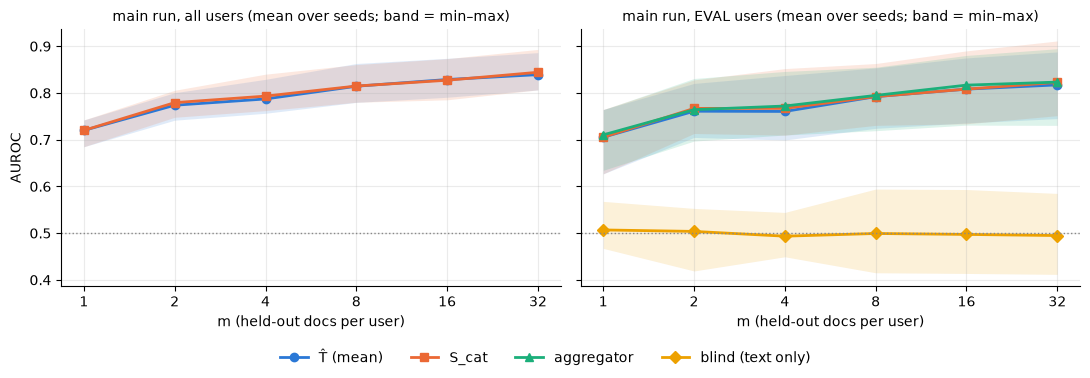

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, g in zip(axes, ["all", "EVAL"]):
    for st in A.STATS:
        x = per_seed[(per_seed.run == "main") & (per_seed.users == g) & (per_seed.stat == st)]
        if x.empty: continue
        s = x.groupby("m").auroc.agg(["mean", "min", "max"])
        ax.fill_between(s.index, s["min"], s["max"], color=COL[st], alpha=.15, lw=0)
        ax.plot(s.index, s["mean"], marker=MRK[st], color=COL[st], lw=2, ms=6, label=NAME[st])
    ax.axhline(.5, color="#888", lw=1, ls=":")
    ax.set_xscale("log", base=2); ax.set_xticks(A.DR.M_GRID, A.DR.M_GRID)
    ax.set_xlabel("m (held-out docs per user)"); ax.set_title(f"main run, {g} users (mean over seeds; band = min–max)", fontsize=10)
axes[0].set_ylabel("AUROC")
hs, ls = axes[1].get_legend_handles_labels()
fig.legend(hs, ls, frameon=False, loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

## 4. Does any statistic beat T̂? (falsifier 2)
The paired difference AUROC(stat) − AUROC(T̂) on EVAL users, per seed. The spread over seeds **understates** the uncertainty over users, because every seed reuses the same 175 users.

In [6]:
display(A.paired_vs_T(per_seed, "EVAL").round(3))
display(A.paired_vs_T(per_seed[per_seed.stat.isin(["T", "S_cat"])], "all").round(3))

,stat,m,mean_diff,sd,seeds_better,seeds
0,Agg,1,0.005,0.007,7,10
1,Agg,2,0.003,0.010,5,10
2,Agg,4,0.012,0.012,8,10
3,Agg,8,0.003,0.014,5,10
4,Agg,16,0.009,0.020,6,10
5,Agg,32,0.006,0.021,7,10
6,Blind,1,-0.198,0.051,0,10
7,Blind,2,-0.257,0.070,0,10
8,Blind,4,-0.267,0.062,0,10
9,Blind,8,-0.293,0.098,0,10


,stat,m,mean_diff,sd,seeds_better,seeds
0,S_cat,1,-0.000,0.000,0,10
1,S_cat,2,0.006,0.002,10,10
2,S_cat,4,0.006,0.004,9,10
3,S_cat,8,0.000,0.004,5,10
4,S_cat,16,-0.002,0.005,3,10
5,S_cat,32,0.005,0.008,7,10


### 4b. User-bootstrap 95% CIs (plan row 2)
B = 1000 resamples of the 175 users. Each resample is shared by every seed, m, draw and statistic, so the CI covers the
uncertainty over users that the seed spread misses. `diff` = AUROC(stat) − AUROC(T̂), averaged over draws and seeds; `p_gt0` =
share of resamples with diff > 0. Aggregator and blind baseline: the FIT fit is held fixed and only EVAL users are resampled.
There are 12 comparisons per user group (6 m × 2 statistics), so a single CI that just excludes 0 is weak evidence.

In [7]:
uv = A.user_values(sc, cat, texts=texts)
bt = A.bootstrap_vs_T(uv, B=1000)
display(bt[bt.stat != "T"].round(3).reset_index(drop=True))
display(bt[bt.stat == "T"].round(3).reset_index(drop=True))

,users,m,stat,auroc,auroc_lo,auroc_hi,diff,diff_lo,diff_hi,p_gt0
0,EVAL,1,Agg,0.710,0.672,0.751,0.005,-0.006,0.016,0.821
1,EVAL,1,Blind,0.507,0.488,0.528,-0.198,-0.244,-0.154,0.000
2,EVAL,1,S_cat,0.705,0.665,0.748,0.000,0.000,0.000,0.000
3,EVAL,2,Agg,0.764,0.723,0.804,0.003,-0.009,0.016,0.692
4,EVAL,2,Blind,0.504,0.480,0.526,-0.257,-0.303,-0.211,0.000
5,EVAL,2,S_cat,0.767,0.726,0.808,0.006,0.002,0.010,0.997
6,EVAL,4,Agg,0.772,0.731,0.812,0.012,0.002,0.022,0.995
7,EVAL,4,Blind,0.494,0.466,0.522,-0.267,-0.314,-0.218,0.000
8,EVAL,4,S_cat,0.767,0.724,0.809,0.007,0.001,0.013,0.985
9,EVAL,8,Agg,0.795,0.754,0.833,0.003,-0.012,0.018,0.661


,users,m,stat,auroc,auroc_lo,auroc_hi,diff,diff_lo,diff_hi,p_gt0
0,EVAL,1,T,0.705,0.665,0.748,NaN,NaN,NaN,NaN
1,EVAL,2,T,0.761,0.720,0.802,NaN,NaN,NaN,NaN
2,EVAL,4,T,0.760,0.717,0.803,NaN,NaN,NaN,NaN
3,EVAL,8,T,0.792,0.748,0.832,NaN,NaN,NaN,NaN
4,EVAL,16,T,0.808,0.764,0.849,NaN,NaN,NaN,NaN
5,EVAL,32,T,0.817,0.772,0.860,NaN,NaN,NaN,NaN
6,all,1,T,0.720,0.687,0.750,NaN,NaN,NaN,NaN
7,all,2,T,0.774,0.745,0.803,NaN,NaN,NaN,NaN
8,all,4,T,0.787,0.756,0.819,NaN,NaN,NaN,NaN
9,all,8,T,0.814,0.782,0.844,NaN,NaN,NaN,NaN


## 5. Variance decomposition, Prop. 6 (falsifiers 1 and 3)
Per seed: Δ, v_B and v_W for each class. Predicted AUROC(m) = Φ(Δ / √(v_B¹ + v_B⁰ + (v_W¹ + v_W⁰)/m)), and the ceiling at m → ∞.
These are compared with the measured T̂ AUROC (200 random subsets per m). Eq. (3) is an approximation (Gaussian), so a mismatch is informative, not necessarily a failure.

,seed,delta,v_B1,v_B0,v_W1,v_W0,ceiling,share_between_at_m32
0,0,52.555,4552.435,1248.423,2650.059,691.575,0.755,0.982
1,1,56.623,5637.735,1287.162,2889.303,838.827,0.752,0.983
2,2,48.802,2969.144,2084.374,2074.116,1101.162,0.754,0.981
3,3,54.115,6434.920,1191.138,2775.808,832.071,0.732,0.985
4,4,54.892,5763.419,1158.137,2761.258,1021.234,0.745,0.983
5,5,52.387,5904.035,1705.917,2307.489,991.610,0.726,0.987
6,6,53.471,4813.301,1909.195,2229.608,987.840,0.743,0.985
7,7,54.064,6383.836,1027.253,2671.166,1043.212,0.735,0.985
8,8,59.636,6190.948,1747.427,2331.307,763.199,0.748,0.988
9,9,53.651,6872.745,541.111,2761.231,784.807,0.733,0.985


,predicted,measured,ceiling
m,,,
1,0.702,0.726,0.742
2,0.720,0.761,0.742
4,0.730,0.790,0.742
8,0.736,0.812,0.742
16,0.739,0.829,0.742
32,0.741,0.839,0.742


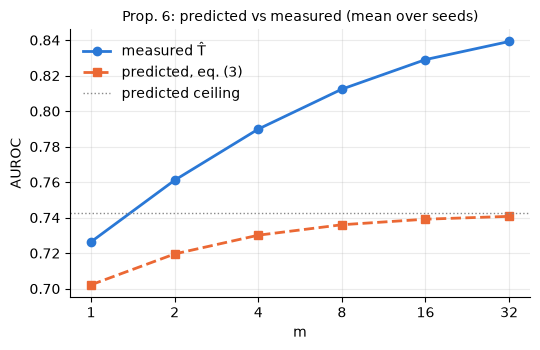

In [8]:
seeds = sorted(sc[sc.run == "main"].seed.unique())
vd = [A.variance_decomposition(sc, "main", s) for s in seeds]
meas = {s: A.measured_T_auroc(sc, "main", s, R=200) for s in seeds}
rows = [{"seed": v["seed"], "m": m, "predicted": v["pred"][m], "measured": meas[v["seed"]][m], "ceiling": v["ceiling"]}
        for v in vd for m in A.DR.M_GRID]
P = pd.DataFrame(rows)
display(pd.DataFrame([{k: v[k] for k in ("seed", "delta", "v_B1", "v_B0", "v_W1", "v_W0", "ceiling", "share_between_at_m32")} for v in vd]).round(3))
display(P.groupby("m")[["predicted", "measured", "ceiling"]].mean().round(3))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
s = P.groupby("m").mean()
ax.plot(s.index, s.measured, marker="o", color=COL["T"], lw=2, label="measured T̂")
ax.plot(s.index, s.predicted, marker="s", color=COL["S_cat"], lw=2, ls="--", label="predicted, eq. (3)")
ax.axhline(s.ceiling.iloc[0], color="#888", lw=1, ls=":", label="predicted ceiling")
ax.set_xscale("log", base=2); ax.set_xticks(A.DR.M_GRID, A.DR.M_GRID); ax.set_xlabel("m"); ax.set_ylabel("AUROC")
ax.set_title("Prop. 6: predicted vs measured (mean over seeds)", fontsize=10); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 5b. EXPLORATORY: eq. (3) on transformed scores (added 2026-11-25, after eq. (3) failed on raw s; not pre-registered)
s is heavy-tailed (a few member users inflate v_B¹), which breaks the Gaussian step of eq. (3). Same decomposition and prediction on
transformed per-document scores, compared with the measured AUROC of the mean of the **same** transformed scores:
`slog` = sign(s)·log(1+|s|); `int` = rank-inverse-normal over all documents of the model.

predicted               measured                  gap               ceiling             
transform       int    raw   slog      int    raw   slog    int    raw   slog     int    raw  slog
m                                                                                                 
1             0.732  0.702  0.702    0.726  0.726  0.726 -0.005  0.024  0.024   0.819  0.742  0.78
2             0.765  0.720  0.732    0.760  0.761  0.751 -0.005  0.042  0.019   0.819  0.742  0.78
4             0.788  0.730  0.752    0.790  0.790  0.769  0.002  0.060  0.017   0.819  0.742  0.78
8             0.802  0.736  0.765    0.813  0.812  0.792  0.010  0.076  0.026   0.819  0.742  0.78
16            0.810  0.739  0.772    0.829  0.829  0.813  0.019  0.090  0.040   0.819  0.742  0.78
32            0.814  0.741  0.776    0.839  0.839  0.826  0.025  0.098  0.050   0.819  0.742  0.78

,mean_abs,max_abs
transform,,
int,0.012,0.042
raw,0.065,0.133
slog,0.029,0.074


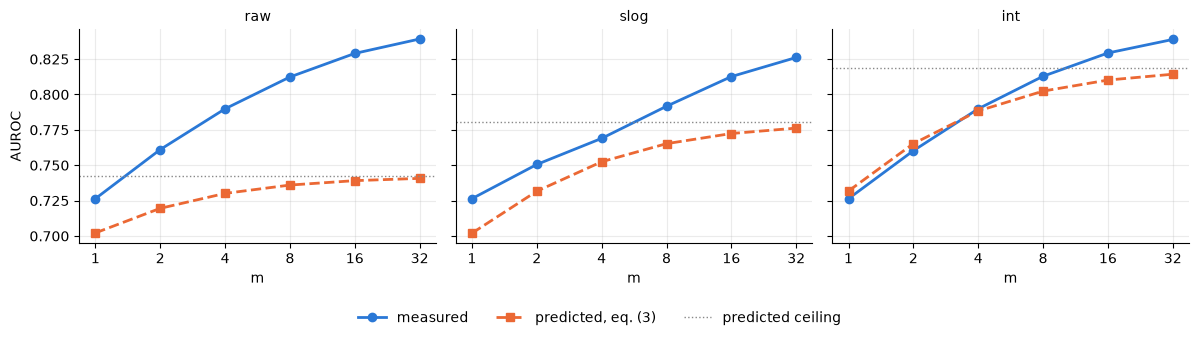

In [9]:
rows = []
for tr in A.TRANSFORMS:
    for s_ in seeds:
        v = A.variance_decomposition(sc, "main", s_, transform=tr)
        me = meas[s_] if tr is None else A.measured_T_auroc(sc, "main", s_, R=200, transform=tr)
        rows += [{"transform": v["transform"], "seed": s_, "m": m, "predicted": v["pred"][m], "measured": me[m],
                  "ceiling": v["ceiling"]} for m in A.DR.M_GRID]
PT = pd.DataFrame(rows).assign(gap=lambda x: x.measured - x.predicted)
display(PT.groupby(["transform", "m"])[["predicted", "measured", "gap", "ceiling"]].mean().round(3).unstack(0))
display(PT.groupby("transform").gap.agg(mean_abs=lambda x: x.abs().mean(), max_abs=lambda x: x.abs().max()).round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, tr in zip(axes, ["raw", "slog", "int"]):
    s = PT[PT["transform"] == tr].groupby("m").mean(numeric_only=True)
    ax.plot(s.index, s.measured, marker="o", color=COL["T"], lw=2, label="measured")
    ax.plot(s.index, s.predicted, marker="s", color=COL["S_cat"], lw=2, ls="--", label="predicted, eq. (3)")
    ax.axhline(s.ceiling.iloc[0], color="#888", lw=1, ls=":", label="predicted ceiling")
    ax.set_xscale("log", base=2); ax.set_xticks(A.DR.M_GRID, A.DR.M_GRID); ax.set_xlabel("m"); ax.set_title(tr, fontsize=10)
axes[0].set_ylabel("AUROC")
hs, ls = axes[0].get_legend_handles_labels()
fig.legend(hs, ls, frameon=False, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

## 6. Null model (seed 0, EVAL users never trained on, fake labels)
Every statistic must show J ≈ 0: the certificate is ≤ 0 at every m. The aggregator is fit on FIT users, who carry real training signal in the null model, and applied to EVAL.

In [10]:
nl = per_seed[per_seed.run == "null"]
if nl.empty:
    print("no null run yet")
else:
    display(nl.pivot_table(index="m", columns="stat", values=["auroc", "dkw_cert"]).round(3))
    bad = ev[(ev.run == "null") & (ev.dkw_cert > 0)]
    print("null PASS: no positive DKW certificate in any (stat, m, draw)" if bad.empty else "null FAIL:")
    if not bad.empty: display(bad)

auroc                      dkw_cert                     
stat    Agg  Blind  S_cat      T      Agg  Blind  S_cat      T
m                                                             
1     0.501  0.518  0.494  0.494   -0.354 -0.318 -0.359 -0.359
2     0.481  0.487  0.489  0.490   -0.340 -0.361 -0.353 -0.344
4     0.510  0.482  0.525  0.527   -0.315 -0.357 -0.286 -0.282
8     0.532  0.471  0.529  0.532   -0.276 -0.366 -0.302 -0.295
16    0.526  0.414  0.529  0.537   -0.287 -0.391 -0.298 -0.286
32    0.552  0.412  0.542  0.548   -0.234 -0.431 -0.256 -0.251

null PASS: no positive DKW certificate in any (stat, m, draw)


## 7. Blind baseline (text only, no model)
Under a random user-level split, it must stay at chance. A positive certificate would mean the split or the preprocessing leaks.

In [11]:
b = per_seed[(per_seed.run == "main") & (per_seed.stat == "Blind")]
display(b.groupby("m")[["auroc", "j_hat", "dkw_cert"]].agg(["mean", "max"]).round(3))

auroc         j_hat        dkw_cert       
     mean    max   mean    max     mean    max
m                                             
1   0.507  0.568  0.126  0.175   -0.323 -0.273
2   0.504  0.553  0.125  0.208   -0.323 -0.241
4   0.494  0.544  0.107  0.166   -0.342 -0.282
8   0.499  0.594  0.130  0.238   -0.319 -0.211
16  0.497  0.593  0.118  0.217   -0.331 -0.231
32  0.495  0.585  0.114  0.243   -0.334 -0.206

## Notes (to fill after reading the results)
- Training (best epochs):
- Headline certificate (seed 1):
- T̂ vs S_cat vs aggregator (falsifier 2):
- Saturation and the predicted ceiling (falsifier 1):
- Predicted vs measured AUROC (falsifier 3):
- Null model:
- Blind baseline:
- Decision: